In [299]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import pandas as pd

torch.manual_seed(1)

print(torch.__version__)

2.12.0+cu130


In [300]:
def LinearEquation():
    A = torch.tensor([
        [0., 1.],
        [1., 1.],
        [2., 1.],
        [3., 1.]
    ])

    B = torch.tensor([
        [-1.0],
        [ 0.2],
        [ 0.9],
        [ 2.1]
    ])

    print(A)
    print(A.shape)

    print(B)
    print(B.shape)



if __name__ == "__main__":
    LinearEquation()

tensor([[0., 1.],
        [1., 1.],
        [2., 1.],
        [3., 1.]])
torch.Size([4, 2])
tensor([[-1.0000],
        [ 0.2000],
        [ 0.9000],
        [ 2.1000]])
torch.Size([4, 1])


In [301]:
def DataForLinearRegression():
    A_prime = torch.tensor([[0.],
                            [1.],
                            [2.],
                            [3.]])
    
    B_prime = torch.tensor([[-1.], 
                            [0.2], 
                            [0.9],
                            [2.1]])
    return A_prime, B_prime


    
def PrintInfo_Tensor(tensor_A, tensor_B): # check point 1.
    print(tensor_A, tensor_A.shape) 
    print(tensor_B, tensor_B.shape)
    

if __name__ == "__main__":
    X, Y = DataForLinearRegression()
    PrintInfo_Tensor(X, Y)



tensor([[0.],
        [1.],
        [2.],
        [3.]]) torch.Size([4, 1])
tensor([[-1.0000],
        [ 0.2000],
        [ 0.9000],
        [ 2.1000]]) torch.Size([4, 1])


# Q1.
---
* [4,]는 1차원으로, row 하나만 존재하는 텐서이고, ([4,1])은 1개의 원소를 가진 row가 총 4개(column)이란 의미로, 입력에 보다 적합한 구조임
* 또한 nn.linear()는 입력 및 출력에 대한 차원이 필요하기 때문에 명시적으로 각 axis에 대한 차원을 입력해야함

---

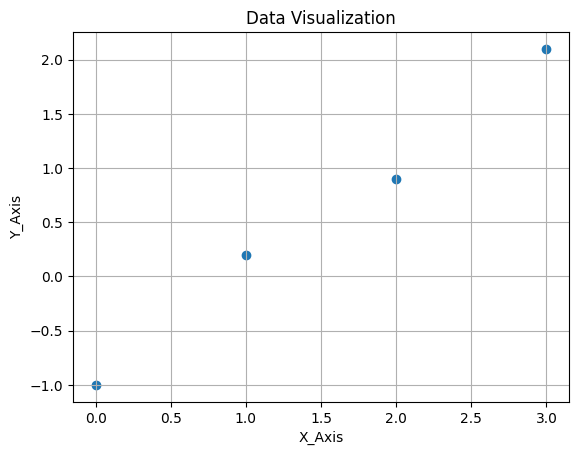

Pearson correlation coefficient: 0.9950371384620667


In [302]:
def Data_Visualization():
    x_axis, y_axis = DataForLinearRegression()
    plt.scatter(x_axis, y_axis)
    plt.title("Data Visualization")
    plt.xlabel("X_Axis")
    plt.ylabel("Y_Axis")
    plt.grid()
    plt.show()



def PearsonCorrelationFormula(values_x, values_y):  # for Q2.
    deviation_x = values_x - values_x.mean()
    deviation_y = values_y - values_y.mean()

    covariance_XY = torch.sum(deviation_x * deviation_y)
    std_dev_XY = torch.sqrt(torch.sum(deviation_x ** 2) * torch.sum(deviation_y ** 2))
    correlation_coefficient = covariance_XY / std_dev_XY

    return correlation_coefficient



if __name__ == "__main__":
    X, Y = DataForLinearRegression()
    Data_Visualization()

    correlation = PearsonCorrelationFormula(X, Y)
    print("Pearson correlation coefficient:", correlation.item())

# Q2.
---
* 두 데이터셋의 상관계수를 계산했을때 약 0.995로, 매우 강한 양의 상관관계를 띈다
---

In [303]:
def Generate_LinearModel():
    model = nn.Linear(
    in_features = 1,
    out_features = 1,
    bias = False
    )
    return model



def PrintLinearModel(model): # check point 2.
    print(model)
    for name, param in model.named_parameters():
        print(name, param)



if __name__ == "__main__":
    model = Generate_LinearModel()
    PrintLinearModel(model)


Linear(in_features=1, out_features=1, bias=False)
weight Parameter containing:
tensor([[0.5153]], requires_grad=True)


# Q3.
---
* 모델의 입출력에 대한 feature가 각각 1개
---

# Q4.
---
* 퍼셉트론은 기본적으로 Y = wX + b 이지만, 현재 조건에서 bias는 존재하지 않으므로 False로 설정
---

In [304]:
def Prediction_BeforeTraining():
    A_prime, B_prime = DataForLinearRegression()
    model = Generate_LinearModel()
    prediction = model(A_prime)

    return model, prediction, B_prime


def Print_Prediction_BeforeTraining(model, prediction, B_prime):
    print(f"Weight that before training : {model.weight}")
    print(f"Prediction that before training : {prediction}")
    print(f"Actual values : {B_prime}")


if __name__ == "__main__":
    model, prediction, B_prime = Prediction_BeforeTraining()
    Print_Prediction_BeforeTraining(model, prediction, B_prime)

Weight that before training : Parameter containing:
tensor([[-0.4414]], requires_grad=True)
Prediction that before training : tensor([[ 0.0000],
        [-0.4414],
        [-0.8828],
        [-1.3241]], grad_fn=<MmBackward0>)
Actual values : tensor([[-1.0000],
        [ 0.2000],
        [ 0.9000],
        [ 2.1000]])


# Q5.
---
* 말 그대로 학습을 하지 않았기 때문으로, 튜닝을 통해 해당 모델의 최적해를 찾는 과정을 거쳐야함
---

In [305]:
def Loss_Function():
    A_prime, B_prime = DataForLinearRegression()
    model = Generate_LinearModel()
    
    prediction = model(A_prime)
    loss = F.mse_loss(prediction, B_prime)

    print(loss)

    return loss.item()

    


if __name__ == "__main__": 
    Loss_Function()

tensor(2.5011, grad_fn=<MseLossBackward0>)


# Q6.
---
* 다른 성능평가 지표보다 연산비용이 적고, Residual이 1보다 크거나 작을때 차이가 극명히 드러남
---

In [306]:
def Setup_Optimizer(model):
    optimizer = torch.optim.SGD(
        model.parameters(),
        lr = 0.005
    )
    return optimizer

def LearningProcess(A_prime, B_prime, model, optimizer):      # 10-1 epoch의 학습과정 이해
    # 1. Prediction
    prediction = model(A_prime)
    # 2. Loss 계산
    loss = F.mse_loss(prediction, B_prime)
    # 3. 기존 Gradient 초기화
    optimizer.zero_grad()
    # 4. Gradient 계산
    loss.backward()
    # 5. Parameter 업데이트
    optimizer.step()
    return loss



if __name__ == "__main__":
    optimizer = Setup_Optimizer(Generate_LinearModel())
    print(optimizer)

SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.005
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)


# Q7.
---
* optimizer.zero_grad() : gradient 초기화

* loss.backward() : Backpropagation을 통해 gradient 계산

* optimizer.step() : 계산된 gradient를 통해 weight 업데이트
---

In [307]:
def Check_Gradient():
    model = Generate_LinearModel()
    for name, param in model.named_parameters():
        print("Parameter:", name)
        print("Value:", param.data)
        print("Gradient:", param.grad)


if __name__ == "__main__":
    Check_Gradient()

Parameter: weight
Value: tensor([[-0.9414]])
Gradient: None


# Q8.
---
* param.data : 가중치
* param.grad : 가중치의 기울기
---

In [308]:
def Training_LinearModel():
    A_prime, B_prime = DataForLinearRegression()
    model = Generate_LinearModel()
    optimizer = Setup_Optimizer(model)

    loss_history = []

    for epoch in range(1000):
        loss_value = LearningProcess(
            A_prime,
            B_prime,
            model,
            optimizer
        )

        loss_history.append(loss_value.item())

        if epoch % 100 == 0:
            print(f"Epoch {epoch} | Loss: {loss_value.item():.6f}")

    return model, loss_history
        
def Print_TrainingResults(A_prime,model):
    for name, param in model.named_parameters():
        print(name, param.data)

    with torch.no_grad():
        prediction = model(A_prime)
        print(f"Prediction after training: {prediction}")

    

if __name__ == "__main__":
    model, loss_history = Training_LinearModel()
    A_prime, _ = DataForLinearRegression()
    print()
    print("Training Results:")
    Print_TrainingResults(A_prime, model)

Epoch 0 | Loss: 0.334986
Epoch 100 | Loss: 0.334822
Epoch 200 | Loss: 0.334821
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821

Training Results:
weight tensor([[0.5929]])
Prediction after training: tensor([[0.0000],
        [0.5929],
        [1.1857],
        [1.7786]])


# Q9.
---
*   before training : [0.0000],
    [0.5929],
    [1.1857],
    [1.7786]

    after training : [0.0000],
    [-0.4414],
    [-0.8828],
    [-1.3241]

    위 처럼 변화하였는데, weight가 -0.4414에서 0.5929로 바뀌었다

---

Epoch 0 | Loss: 2.566890
Epoch 100 | Loss: 0.336617
Epoch 200 | Loss: 0.334823
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821


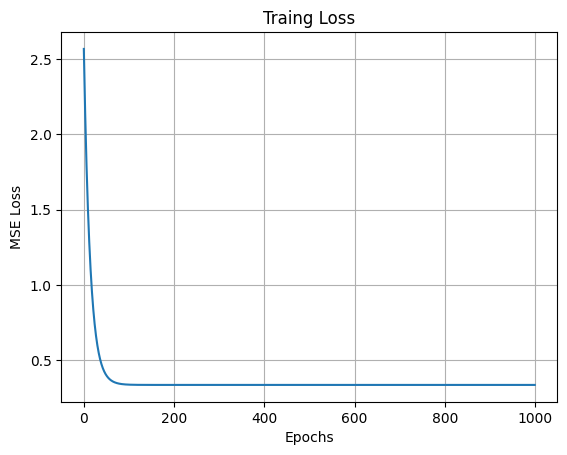

In [309]:
def Visualize_LossHistory(loss_history):
    plt.plot(loss_history)
    plt.title("Traing Loss")
    plt.xlabel("Epochs")
    plt.ylabel("MSE Loss")
    plt.grid(True)
    plt.show()


if __name__ == "__main__":
    model, loss_history = Training_LinearModel()
    A_prime, _ = DataForLinearRegression()
    Visualize_LossHistory(loss_history)

# Q10.
---
* 대락 80 epoch 부근에서 특정 값(0.3348)으로 수렴한 모습을 보임
    
    또한 Loss는 크게 감소
---

# Q11.
---
* Residual이 점점 감소하여 y_hat이 실제 y에 수렴해간다는 뜻
---

Epoch 0 | Loss: 0.359584


Epoch 100 | Loss: 0.334841
Epoch 200 | Loss: 0.334821
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821
Epoch 0 | Loss: 2.125617
Epoch 100 | Loss: 0.336262
Epoch 200 | Loss: 0.334823
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821
Prediction after training: tensor([[0.0000],
        [0.5929],
        [1.1857],
        [1.7786]])


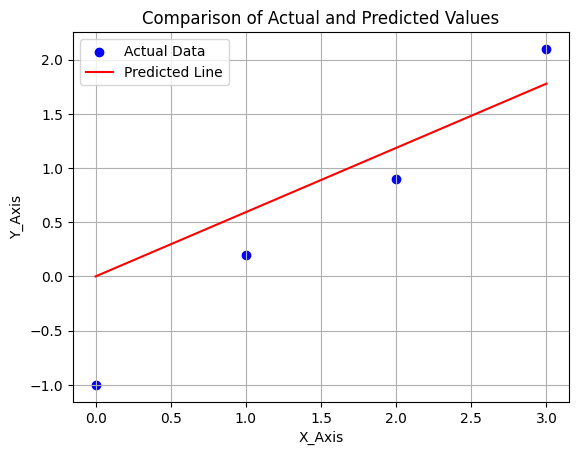

In [310]:
def Comparision_BothModels():
    Training_LinearModel()
    Prediction_BeforeTraining()
    A_prime, B_prime = DataForLinearRegression()
    model, _ = Training_LinearModel()
    
    with torch.no_grad():
        prediction = model(A_prime)
        print(f"Prediction after training: {prediction}")

    plt.scatter(A_prime, B_prime, label="Actual Data", color='blue')
    plt.plot(A_prime, prediction, label="Predicted Line", color='red')
    plt.title("Comparison of Actual and Predicted Values")
    plt.xlabel("X_Axis")
    plt.ylabel("Y_Axis")
    plt.legend()
    plt.grid()
    plt.show()

if __name__ == "__main__":
    Comparision_BothModels()

# Q12.
---
* 모든 점을 지나지 않으며, bias를 배제한 채로 학습시킨 것이 원인이라 생각합니다.
---

 Learning Rate  초기 Loss  100 Epoch Loss  1000 Epoch Loss     최종 w
         0.001 0.683204        0.421519         0.334822 0.592576
         0.010 0.683204        0.334822         0.334821 0.592857
         0.100 0.683204        0.334821         0.334821 0.592857


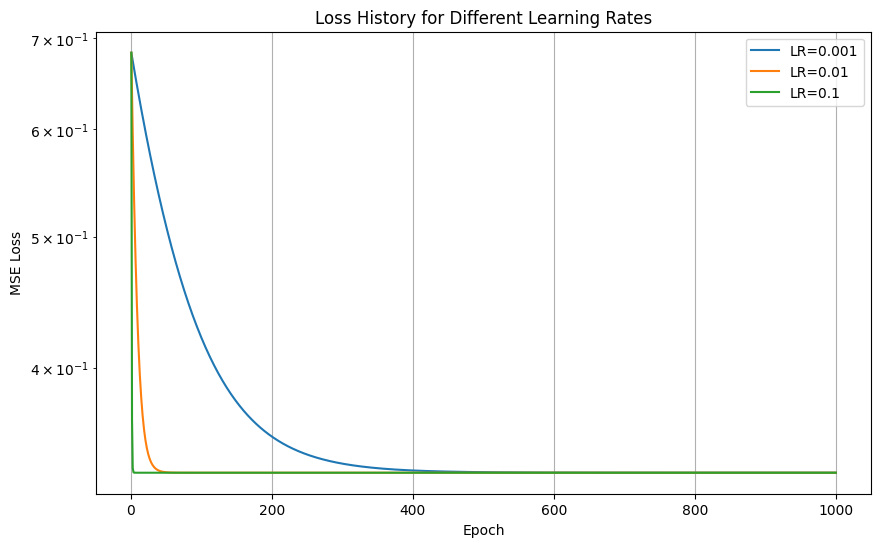

In [311]:
def Comparision_LearnigRate():
    learning_rates = [0.001, 0.01, 0.1]
    A_prime, B_prime = DataForLinearRegression()
    initial_model = Generate_LinearModel()
    initial_state = initial_model.state_dict()
    comparison = {}
    epochs = 1000

    for lr in learning_rates:
        model = Generate_LinearModel()
        model.load_state_dict(initial_state)
        optimizer = torch.optim.SGD(model.parameters(), lr=lr)
        loss_history = []

        with torch.no_grad():
            initial_loss = F.mse_loss(model(A_prime), B_prime).item()

        for epoch in range(epochs):
            loss_value = LearningProcess(A_prime, B_prime, model, optimizer)
            loss_history.append(loss_value.item())

        with torch.no_grad():
            final_loss = F.mse_loss(model(A_prime), B_prime).item()

        comparison[lr] = {
            "loss_history": loss_history,
            "initial_loss": initial_loss,
            "loss_after_100_epochs": loss_history[99],
            "final_loss": final_loss,
            "final_w": model.weight.item(),
        }

    return comparison

def tableOfLossHistory(comparison):
    rows = []
    for lr, result in comparison.items():
        rows.append({
            "Learning Rate": lr,
            "초기 Loss": result["initial_loss"],
            "100 Epoch Loss": result["loss_after_100_epochs"],
            "1000 Epoch Loss": result["final_loss"],
            "최종 w": result["final_w"],
        })
    return pd.DataFrame(rows).round(6)

def Visualize_LossHistory(comparison):
    plt.figure(figsize=(10, 6))
    for lr, result in comparison.items():
        history = result["loss_history"]
        plt.plot(range(1, len(history) + 1), history, label=f"LR={lr}")
    plt.title("Loss History for Different Learning Rates")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.yscale("log")
    plt.legend()
    plt.grid(True)
    plt.show()


if __name__ == "__main__":
    comparison = Comparision_LearnigRate()
    print(tableOfLossHistory(comparison).to_string(index=False))
    Visualize_LossHistory(comparison)

# Q13.
---
* lr = 0.1 이 가장 빠르게 감소함
---

# Q14.
---
* Minimum Loss function에 도달하는 시간이 너무 길어짐

    또한 local minimum 근처에서 과적합 위험 증가

---

# Q15.
---
* Q14와는 정반대로 최적해까지 빠르게 도달할 수 있지만, 조건을 충분히 만족시키는 local minimum을 지나치기 쉽고 발산 혹은 진동의 위험도 있으나, 이번 실험에서 그러한 결과가 나타나지 않음

    따라서 η = 0.1은 상대적으로 크지않은 rate라 생각됨.

---

In [312]:
def Directly_Optimize_Weight():
    A_prime, B_prime = DataForLinearRegression()

    AT = A_prime.t()

    ATA = AT @ A_prime
    ATA_inv = torch.inverse(ATA)
    ATB = AT @ B_prime
    w_pseudo = ATA_inv @ ATB


    return AT, w_pseudo


def Print_PseudoInverseWeight(AT, w_pseudo):
    print(f"{AT, AT.shape}")
    print("Pseudo-inverse w:", f"{w_pseudo.item()}")

if __name__ == "__main__":
    AT, w_pseudo = Directly_Optimize_Weight()
    Print_PseudoInverseWeight(AT, w_pseudo)

(tensor([[0., 1., 2., 3.]]), torch.Size([1, 4]))
Pseudo-inverse w: 0.5928571224212646


# 18. Matrix Shape 확인
---

| Tensor | Shape |
| --- | --- |
| `A_prime` | (4,1) |
| `A_prime.T` | (1,4) |
| `A_prime.T @ A_prime` | (1,1) |
| `(A_prime.T @ A_prime)^-1` | (1,1) |
| `A_prime.T @ B_prime` | (1,1) |
| `w_pseudo` | (1,1) |

---

# Q16.
---
* A_prime.shape = (4,1)

    A_prime^T.shape = (1,4)이므로

    A_prime^T * A_prime 는 shape이 (1,1) 인 스칼라값 생성 가능

# 19. 두 결과 비교
---

| 방법 | 구한 w	| 특징 |
| --- | --- | --- |
| Gradient Descent	| 0.5929 | 반복적인 학습을 통해 해를 찾음 |
| Pseudo-inverse | 0.5928 | 행렬 연산을 이용하여 직접 계산 |

---

In [313]:
def Substract_w():
    model, _ = Training_LinearModel()
    w_gradient = model.weight.detach()

    _, w_pseudo = Directly_Optimize_Weight()
    difference = torch.abs(w_gradient - w_pseudo)

    print(difference)

if __name__ == "__main__":
    Substract_w()

Epoch 0 | Loss: 1.886176
Epoch 100 | Loss: 0.336069
Epoch 200 | Loss: 0.334822
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821
tensor([[8.3447e-07]])


# Q17.
---
* 소숫점 7자리부터 차이가 나기 시작하는 매우 비슷한 값임
---

# Q18.
---
1. SGD의 반복횟수 제한 : 현재 학습횟수는 1000 epoch로 최적해에 완전히 도달하지 못했을 가능성이 있음.
2. Learning Rate : η 를 비교적 작은 값으로 설정해, 접근하는 속도의 한계가 있을 것으로 사료됨
3. 하드웨어적 오차 : float형 연산에선 미세한 오차가 발생 가능
---

In [319]:
def Prediction_forInputValue(input_values):
    model, _ = Training_LinearModel()

    with torch.no_grad():
        for value in input_values:
            x = torch.tensor([[value]], dtype=torch.float32)
            prediction = model(x)
            print(f"x = {value}, wx = {prediction.item():.6f}")



if __name__ == "__main__":
    Prediction_forInputValue([0.0, 1.0, 2.0, 3.0])


Epoch 0 | Loss: 0.612498
Epoch 100 | Loss: 0.335045
Epoch 200 | Loss: 0.334822
Epoch 300 | Loss: 0.334821
Epoch 400 | Loss: 0.334821
Epoch 500 | Loss: 0.334821
Epoch 600 | Loss: 0.334821
Epoch 700 | Loss: 0.334821
Epoch 800 | Loss: 0.334821
Epoch 900 | Loss: 0.334821
x = 0.0, wx = 0.000000
x = 1.0, wx = 0.592856
x = 2.0, wx = 1.185713
x = 3.0, wx = 1.778569


# Q19.
---
* 모델이 출력한 값 [0.0000],
        [0.5929],
        [1.1857],
        [1.7786]

* 직접 계산한 값 [0.0000], [0.5928], [1.1857], [1.7785]

    완전히 동일한 값이 출력되는데,(round() 이전)
    $$|\hat{y_1} - \hat{y_2}| = |w\hat{x_1} - w\hat{x_2}|$$

    가 성립하기 때문임

---

# Q20.
---
* ` optimizer.zero_grad() ` 가 생략됨
---

* 수정된 코드 


` model = nn.Linear(1,1,bias=False) `

` optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
) ` 

` for epoch in range(1000): `

     prediction = model(A_prime)

     loss = F.mse_loss(prediction, B_prime)

     optimizer.zero_grad()

     loss.backward()

     optimizer.step() `
---

# Q21.
---
* 가중치가 점점 누적되어 의도한 것과 다른 학습이 진행됨
---